# Minggu 2 — Topik 3: eksperimen inti

Sesuai draf minggu 2: **profil RMS dan spektrum**, **4 SNR × 20 campuran noise**, **spectral subtraction**, lalu uji **Kruskal–Wallis (+Dunn)**, **Wilcoxon (SNR)**, dan **Spearman (CSV USDA)**.

Notebook ini berdiri sendiri: membaca WAV mentah di `../data/raw`, mengulang praproses minggu 1 (resample → highpass), jadi tidak bergantung pada hasil di `../data/processed`.

**Keputusan tim yang harus dicek di sel parameter** (ditandai `# KEPUTUSAN TIM`):
1. `FS_BERSAMA` (maksimal 20000 karena A8–A9 hanya 20 kHz).
2. `ESC_KELAS`: kelas noise Topik 1 yang dipakai (jalankan sel diagnostik noise dulu, dan dengarkan klipnya).
3. Noise ikut di-highpass sama seperti sinyal, dan **SNR didefinisikan pada sinyal setelah highpass**. Noise Bug Bytes (I3, I4, I6) hampir semua energinya di bawah 200 Hz, jadi setelah highpass sisanya diperbesar untuk mencapai SNR target. Karena itu hasil dilaporkan **terpisah** per kelompok noise (BugBytes vs ESC50).

**Urutan sel:** parameter → fungsi → profil (A) → H1 → noise → eksperimen SNR + spectral subtraction (B) → H2 → CSV USDA + H3 → checklist.

In [1]:
import glob, os, re, json, time
from fractions import Fraction
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
from scipy import stats
from scipy.io import wavfile
from scipy.signal import butter, sosfiltfilt, resample_poly, stft, istft, welch

RAW  = "../data/raw"
BIRD = "../data/bird_sounds"          # folder dataset Topik 1 (berisi info.labels)
RES  = "../results"
os.makedirs(RES, exist_ok=True)

# ---------------- parameter (sesuai draf) ----------------
FS_BERSAMA = 20000     # KEPUTUSAN TIM: harus <= fs terkecil file hama/noise yang dipakai (A8-A9 = 20 kHz)
HP_HZ      = 200       # highpass 200 Hz
FRAME_S    = 0.01      # RMS per frame 10 ms
K_MAD      = 3         # ambang event = median + 3*MAD
SNR_LIST   = [-5, 0, 5, 10]
N_POTONG   = 20        # potongan noise acak per tingkat SNR
ALPHAS     = [1.0, 2.0]  # over-subtraction 1-2
BETA       = 0.01      # spectral floor
NPERSEG, NOVERLAP = 1024, 768    # STFT Hann 1024, overlap 75% (memenuhi syarat rekonstruksi)
QUIET_PCT  = 20        # estimasi noise dari 20% frame STFT berenergi terendah (tanpa "contekan" noise asli)
SEED       = 42
ALPHA_SIG  = 0.05      # tingkat signifikansi uji statistik

# noise Bug Bytes (rekaman akselerometer, kategori I; I5/I7 dibuang karena ada larva)
NOISE_BB = ["I3", "I4", "I6"]

# KEPUTUSAN TIM: kelas noise Topik 1 (nomor kelas menurut urutan ESC-50). Verifikasi dengan mendengarkan klipnya.
ESC_KELAS    = {10: "hujan", 44: "mesin", 30: "ketukan pintu"}
ESC_KATEGORI = ["training"]     # tambahkan "testing" bila klip kurang
ESC_KLIP_MAKS = 40              # maksimal klip per kelas yang disambung jadi satu kolam noise

# kode -> (peran, spesies, sensor, keterangan)   [identitas A8-A9 sudah dicek dari CSV inventaris]
META = {
    "A3": ("hama", "S. oryzae", "PVDF",              "larva dalam gandum"),
    "A4": ("hama", "S. oryzae", "akselerometer",     "larva dalam gandum"),
    "A5": ("hama", "S. oryzae", "ultrasonik 40 kHz", "larva dalam gandum"),
    "A6": ("hama", "S. oryzae", "ultrasonik 30 kHz", "larva dalam gandum"),
    "A7": ("hama", "S. oryzae", "piezoelektrik",     "larva dalam gandum"),
    "A8": ("hama", "S. zeamais", "mikrofon",         "larva dalam jagung"),
    "A9": ("hama", "S. zeamais", "mikrofon",         "dewasa dalam jagung"),
    # opsional (hama gudang lain, juga mikrofon, jagung) bila tim sepakat menambah:
    # "A10": ("hama", "P. truncatus", "mikrofon", "larva dalam jagung"),
    # "A11": ("hama", "P. truncatus", "mikrofon", "dewasa dalam jagung"),
}

print("python libs -> numpy", np.__version__, "| scipy", scipy.__version__, "| pandas", pd.__version__)
print("parameter siap")

python libs -> numpy 2.2.4 | scipy 1.15.2 | pandas 2.2.3
parameter siap


## Fungsi dasar (sama dengan minggu 1, ditambah indeks frame dan fitur per event)

In [2]:
def baca_wav(path):
    fs, x = wavfile.read(path)
    x = x.astype(float)
    if x.ndim > 1:
        x = x.mean(axis=1)
    return fs, x - x.mean()

def resample_ke(x, fs, fs_baru):
    if fs == fs_baru:
        return x
    r = Fraction(fs_baru, fs)
    return resample_poly(x, r.numerator, r.denominator)

def highpass(x, fs, fc=HP_HZ, order=4):
    sos = butter(order, fc, btype="highpass", fs=fs, output="sos")
    return sosfiltfilt(sos, x)

def proses(x, fs):
    # urutan praproses: resample -> highpass
    return highpass(resample_ke(x, fs, FS_BERSAMA), FS_BERSAMA)

def rms_frame(x, fs=FS_BERSAMA, frame_s=FRAME_S):
    n = int(round(fs * frame_s))
    m = len(x) // n
    return np.sqrt((x[:m * n].reshape(m, n) ** 2).mean(axis=1))

def deteksi_event(rms, frame_s=FRAME_S, k=K_MAD):
    med = np.median(rms)
    mad = np.median(np.abs(rms - med))
    ambang = med + k * mad
    aktif = rms > ambang
    d = np.diff(np.concatenate([[0], aktif.astype(int), [0]]))
    mulai, akhir = np.where(d == 1)[0], np.where(d == -1)[0]
    ev = pd.DataFrame({"f_mulai": mulai, "f_akhir": akhir})
    ev["mulai_s"] = ev.f_mulai * frame_s
    ev["akhir_s"] = ev.f_akhir * frame_s
    ev["durasi_ms"] = (ev.akhir_s - ev.mulai_s) * 1000
    ev["jeda_ke_berikut_s"] = ev.mulai_s.shift(-1) - ev.akhir_s
    return ev, ambang

def fitur_event(y, fs, ev, rms, nfft=2048):
    # fitur per event. rasio_dB = RMS event dibanding RMS latar (median RMS frame) -> tidak bergantung skala sensor
    latar = max(np.median(rms), 1e-12)
    f = np.fft.rfftfreq(nfft, 1 / fs)
    baris = []
    for r in ev.itertuples():
        seg = y[int(r.mulai_s * fs): int(r.akhir_s * fs)]
        if len(seg) < 8:
            continue
        P = np.abs(np.fft.rfft(seg * np.hanning(len(seg)), n=nfft)) ** 2
        if P.sum() == 0:
            continue
        er = float(np.sqrt(np.mean(seg ** 2)))
        baris.append({"durasi_ms": r.durasi_ms, "rms_abs": er,
                      "rasio_dB": 20 * np.log10(er / latar + 1e-12),
                      "f_dom_Hz": float(f[P.argmax()]),
                      "centroid_Hz": float((f * P).sum() / P.sum())})
    return pd.DataFrame(baris)

def cari_file(kode):
    c = sorted(glob.glob(f"{RAW}/{kode}-*.wav"))
    return c[0] if c else None

def rank_biserial(d):
    d = np.asarray(d, float); d = d[d != 0]
    if len(d) == 0:
        return np.nan
    r = stats.rankdata(np.abs(d))
    wp, wm = r[d > 0].sum(), r[d < 0].sum()
    return (wp - wm) / (wp + wm)

print("fungsi siap")

fungsi siap


## A. Profil RMS dan spektrum per spesies dan sensor

Memuat semua file hama di `META`, memproses (resample → highpass), mendeteksi event (RMS 10 ms, median + 3·MAD), lalu menghitung fitur tiap event.

In [3]:
hasil, fitur_semua, ringkas = {}, [], []
fs_min = []
for kode, (peran, spesies, sensor, ket) in META.items():
    p = cari_file(kode)
    if p is None:
        print(f"[!] {kode}: file tidak ditemukan di {RAW}")
        continue
    fs, x = baca_wav(p)
    fs_min.append(fs)
    y = proses(x, fs)
    rms = rms_frame(y)
    ev, ambang = deteksi_event(rms)
    ft = fitur_event(y, FS_BERSAMA, ev, rms)
    ft.insert(0, "kode", kode); ft.insert(1, "spesies", spesies); ft.insert(2, "sensor", sensor)
    fitur_semua.append(ft)
    hasil[kode] = dict(y=y, rms=rms, ev=ev, ambang=ambang, fs_asal=fs)
    dur = len(y) / FS_BERSAMA
    ringkas.append({"kode": kode, "spesies": spesies, "sensor": sensor, "ket": ket,
                    "fs_asal": fs, "durasi_s": round(dur, 1), "n_event": len(ev),
                    "laju_event_per_s": round(len(ev) / dur, 2),
                    "median_durasi_ms": round(ft.durasi_ms.median(), 1) if len(ft) else None,
                    "median_rasio_dB": round(ft.rasio_dB.median(), 1) if len(ft) else None,
                    "median_f_dom_Hz": round(ft.f_dom_Hz.median()) if len(ft) else None,
                    "median_centroid_Hz": round(ft.centroid_Hz.median()) if len(ft) else None})

assert len(hasil) > 0, "tidak ada file hama yang terbaca"
assert FS_BERSAMA <= min(fs_min), f"FS_BERSAMA ({FS_BERSAMA}) > fs terkecil ({min(fs_min)}): akan terjadi upsampling"
fitur_df = pd.concat(fitur_semua, ignore_index=True)
fitur_df.to_csv(f"{RES}/m2_fitur_event.csv", index=False)
profil = pd.DataFrame(ringkas)
profil.to_csv(f"{RES}/m2_profil_per_file.csv", index=False)
profil

,kode,spesies,sensor,ket,fs_asal,durasi_s,n_event,laju_event_per_s,median_durasi_ms,median_rasio_dB,median_f_dom_Hz,median_centroid_Hz
0,A3,S. oryzae,PVDF,larva dalam gandum,25000,10.0,106,10.60,10.0,3.2,6685,5792
1,A4,S. oryzae,akselerometer,larva dalam gandum,25000,10.0,123,12.30,10.0,3.9,1514,3800
2,A5,S. oryzae,ultrasonik 40 kHz,larva dalam gandum,50000,10.0,49,4.90,10.0,1.4,6807,5812
3,A6,S. oryzae,ultrasonik 30 kHz,larva dalam gandum,50000,10.0,35,3.50,10.0,1.2,7168,5772
4,A7,S. oryzae,piezoelektrik,larva dalam gandum,25000,10.0,105,10.50,10.0,9.6,2266,3463
5,A8,S. zeamais,mikrofon,larva dalam jagung,20000,20.9,80,3.83,10.0,3.0,693,3531
6,A9,S. zeamais,mikrofon,dewasa dalam jagung,20000,18.7,175,9.36,10.0,7.7,557,1027


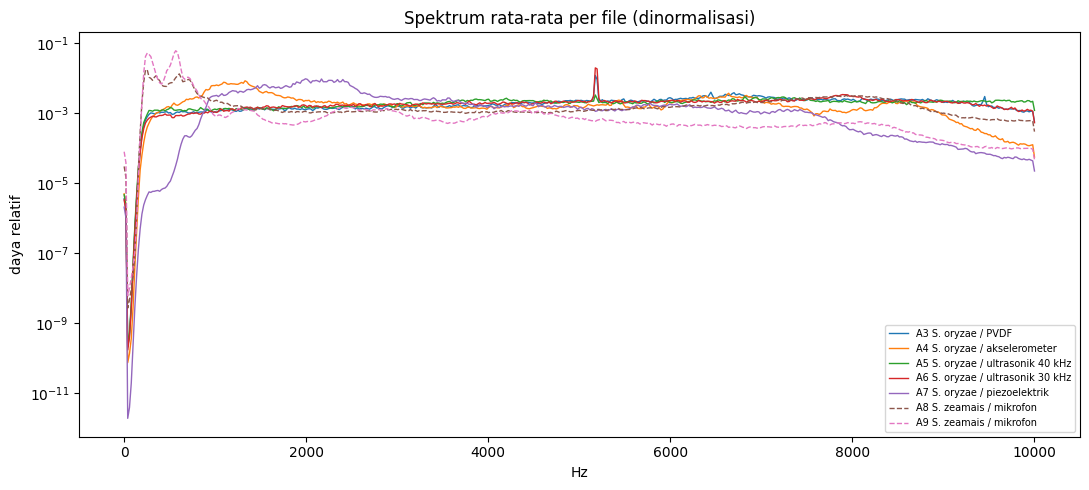

In [4]:
# spektrum rata-rata (Welch, Hann 1024) per file, dinormalisasi supaya bentuknya bisa dibandingkan
fig, ax = plt.subplots(figsize=(11, 5))
for kode, h in hasil.items():
    f, Pxx = welch(h["y"], FS_BERSAMA, window="hann", nperseg=1024)
    ls = "-" if META[kode][1] == "S. oryzae" else "--"
    ax.semilogy(f, Pxx / Pxx.sum(), ls, lw=1, label=f"{kode} {META[kode][1]} / {META[kode][2]}")
ax.set(title="Spektrum rata-rata per file (dinormalisasi)", xlabel="Hz", ylabel="daya relatif")
ax.legend(fontsize=7)
fig.tight_layout()
fig.savefig(f"{RES}/m2_spektrum_per_file.png", dpi=150)
plt.show(); plt.close(fig)

## H1. Perbedaan antar spesies dan antar sensor (Kruskal–Wallis + Dunn)

Unit analisis = **event**. Fitur yang diuji: durasi event, `rasio_dB` (RMS event dibanding latar, supaya tidak bergantung gain tiap sensor), frekuensi dominan, dan spectral centroid. Ukuran efek: ε² (epsilon kuadrat).

Catatan penting untuk laporan: (1) event dari file yang sama tidak sepenuhnya independen; (2) *S. zeamais* hanya direkam dengan mikrofon, jadi perbedaan spesies tercampur dengan perbedaan sensor.

,faktor,fitur,n_grup,n_event,H,p,epsilon2,signifikan
0,spesies,durasi_ms,2,673,39.48,3.312322e-10,0.059,True
1,spesies,rasio_dB,2,673,31.53,1.959837e-08,0.047,True
2,spesies,f_dom_Hz,2,673,302.81,8.048591e-68,0.451,True
3,spesies,centroid_Hz,2,673,277.77,2.304503e-62,0.413,True
4,sensor,durasi_ms,6,673,43.69,2.682502e-08,0.065,True
5,sensor,rasio_dB,6,673,296.37,6.031611e-62,0.441,True
6,sensor,f_dom_Hz,6,673,394.35,4.908772e-83,0.587,True
7,sensor,centroid_Hz,6,673,399.75,3.361283e-84,0.595,True


[!] Dunn butuh scikit-posthocs: jalankan  pip install scikit-posthocs  lalu ulangi sel ini


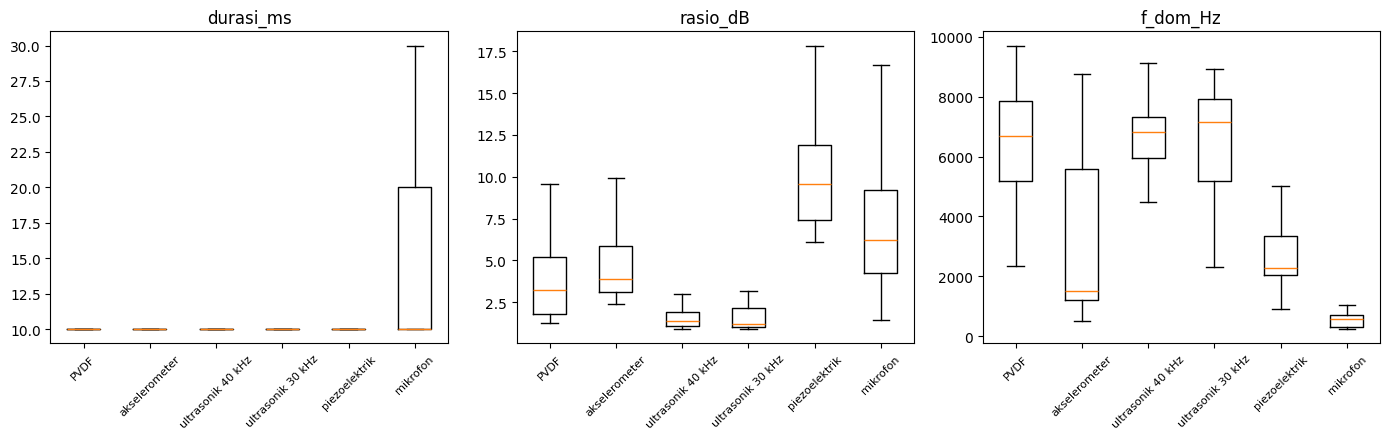

In [5]:
FITUR = ["durasi_ms", "rasio_dB", "f_dom_Hz", "centroid_Hz"]
MIN_PER_GRUP = 5

def kruskal_es(grups):
    H, p = stats.kruskal(*grups)
    n = sum(len(g) for g in grups)
    return H, p, H * (n + 1) / (n ** 2 - 1)

baris = []
for faktor in ["spesies", "sensor"]:
    kel = {k: g for k, g in fitur_df.groupby(faktor) if len(g) >= MIN_PER_GRUP}
    dibuang = sorted(set(fitur_df[faktor]) - set(kel))
    if dibuang:
        print(f"[!] {faktor}: grup dibuang (event < {MIN_PER_GRUP}): {dibuang}")
    if len(kel) < 2:
        print(f"[!] {faktor}: kurang dari 2 grup, uji dilewati")
        continue
    for ft in FITUR:
        H, p, e2 = kruskal_es([g[ft].values for g in kel.values()])
        baris.append({"faktor": faktor, "fitur": ft, "n_grup": len(kel), "n_event": sum(len(g) for g in kel.values()),
                      "H": round(H, 2), "p": p, "epsilon2": round(e2, 3), "signifikan": p < ALPHA_SIG})
h1 = pd.DataFrame(baris)
h1.to_csv(f"{RES}/m2_h1_kruskal.csv", index=False)
display(h1)

# post-hoc Dunn (Holm) antar sensor
try:
    import scikit_posthocs as sp
    d_sens = fitur_df[fitur_df.groupby("sensor")["sensor"].transform("size") >= MIN_PER_GRUP]
    for ft in FITUR:
        dunn = sp.posthoc_dunn(d_sens, val_col=ft, group_col="sensor", p_adjust="holm")
        dunn.to_csv(f"{RES}/m2_h1_dunn_sensor_{ft}.csv")
    print("Dunn disimpan: m2_h1_dunn_sensor_<fitur>.csv ; contoh (rasio_dB):")
    display(pd.read_csv(f"{RES}/m2_h1_dunn_sensor_rasio_dB.csv", index_col=0).round(4))
except ImportError:
    print("[!] Dunn butuh scikit-posthocs: jalankan  pip install scikit-posthocs  lalu ulangi sel ini")

# gambar sebaran fitur per sensor
fig, ax = plt.subplots(1, 3, figsize=(14, 4.5))
urut = list(fitur_df["sensor"].unique())
for a, ft in zip(ax, ["durasi_ms", "rasio_dB", "f_dom_Hz"]):
    a.boxplot([fitur_df.loc[fitur_df.sensor == s, ft] for s in urut], showfliers=False)
    a.set_xticks(range(1, len(urut) + 1)); a.set_xticklabels(urut, rotation=45, fontsize=8)   # kompatibel semua versi matplotlib
    a.set_title(ft)
fig.tight_layout()
fig.savefig(f"{RES}/m2_h1_fitur_per_sensor.png", dpi=150)
plt.show(); plt.close(fig)

## Noise: diagnostik kelas noise Topik 1 (opsional, tapi disarankan sebelum mengunci `ESC_KELAS`)

Untuk tiap kelas dihitung persen energi di bawah `HP_HZ` (akan hilang oleh highpass) dan di atas 1 kHz. Kelas dengan energi hampir semuanya di bawah 200 Hz tidak cocok sebagai noise. Nama kelas mengikuti urutan ESC-50 standar; **verifikasi dengan mendengarkan klipnya**.

In [6]:
ESC50 = ["dog","rooster","pig","cow","frog","cat","hen","insects","sheep","crow",
         "rain","sea waves","crackling fire","crickets","chirping birds","water drops","wind","pouring water","toilet flush","thunderstorm",
         "crying baby","sneezing","clapping","breathing","coughing","footsteps","laughing","brushing teeth","snoring","drinking sipping",
         "door knock","mouse click","keyboard typing","door wood creaks","can opening","washing machine","vacuum cleaner","clock alarm","clock tick","glass breaking",
         "helicopter","chainsaw","siren","car horn","engine","train","church bells","airplane","fireworks","hand saw"]

def muat_labels():
    with open(f"{BIRD}/info.labels", encoding="utf-8") as f:
        d = json.load(f)
    df = pd.DataFrame(d["files"])
    df["label_kelas"] = df["label"].apply(lambda z: z.get("label"))
    df = df[df.label_kelas == "Noise"].copy()
    df["kelas"] = df["name"].str.split("-").str[-1].astype(int)
    return df

DIAGNOSTIK_ESC = True
if DIAGNOSTIK_ESC:
    try:
        esc = muat_labels()
        esc = esc[esc.category.isin(ESC_KATEGORI)]
        baris = []
        for kls, g in esc.groupby("kelas"):
            pe, ph = [], []
            for pth in g["path"].head(3):
                try:
                    fs, x = wavfile.read(f"{BIRD}/{pth}")
                except FileNotFoundError:
                    continue
                x = x.astype(float); x = x.mean(axis=1) if x.ndim > 1 else x
                x = np.trim_zeros(x - x.mean(), "b")
                if len(x) < 100:
                    continue
                f = np.fft.rfftfreq(len(x), 1 / fs); P = np.abs(np.fft.rfft(x)) ** 2
                pe.append(100 * P[f < HP_HZ].sum() / P.sum()); ph.append(100 * P[f >= 1000].sum() / P.sum())
            if pe:
                baris.append({"kelas": kls, "nama": ESC50[kls], "n_klip_dicek": len(pe),
                              "pct_energi_di_bawah_HP": round(np.mean(pe), 1), "pct_energi_di_atas_1kHz": round(np.mean(ph), 1),
                              "dipakai": kls in ESC_KELAS})
        diag = pd.DataFrame(baris).sort_values("pct_energi_di_bawah_HP")
        diag.to_csv(f"{RES}/m2_diagnostik_noise_esc.csv", index=False)
        display(diag.reset_index(drop=True))
    except FileNotFoundError as e:
        print("[!] info.labels / klip noise Topik 1 tidak ditemukan:", e)

C:\Users\Muhammad Faizal\AppData\Local\Temp\ipykernel_8712\2710606296.py:26: WavFileWarning: Reached EOF prematurely; finished at 441044 bytes, expected 441052 bytes from header.
  fs, x = wavfile.read(f"{BIRD}/{pth}")


,kelas,nama,n_klip_dicek,pct_energi_di_bawah_HP,pct_energi_di_atas_1kHz,dipakai
0,1,rooster,3,0.1,84.5,False
1,0,dog,3,0.2,40.3,False
2,21,sneezing,3,0.2,74.8,False
3,20,crying baby,3,0.3,61.6,False
4,39,glass breaking,3,0.4,88.9,False
5,5,cat,3,0.6,94.6,False
6,11,sea waves,3,0.7,62.3,False
7,38,clock tick,3,1.0,75.8,False
8,13,crickets,3,1.1,98.8,False
9,46,church bells,3,1.1,39.8,False


## Kolam noise

Dua kelompok noise, **dilaporkan terpisah**:
- **BugBytes**: I3, I4, I6 (akselerometer, 15 detik per file).
- **ESC50**: klip kelas terpilih dari Topik 1 (diambil dari `info.labels`). Karena klipnya pendek, klip satu kelas **disambung** jadi satu kolam panjang; tiap klip dinormalkan RMS-nya sebelum disambung, dan keheningan digital di ujung klip dibuang.

Potongan acak diambil dari kolam (dengan *wrap* bila kolam lebih pendek daripada sinyal). Daftar file noise yang dipakai disimpan ke `results/` untuk reproduksibilitas.

In [7]:
def norm_rms(y):
    r = np.sqrt(np.mean(y ** 2))
    return y / r if r > 0 else y

def siapkan_pool():
    pools, daftar = {}, []
    # Bug Bytes
    for kode in NOISE_BB:
        p = cari_file(kode)
        if p is None:
            print(f"[!] noise {kode} tidak ditemukan di {RAW}")
            continue
        fs, x = baca_wav(p)
        pools[f"BB-{kode}"] = dict(grup="BugBytes", pool=norm_rms(proses(x, fs)))
        daftar.append({"grup": "BugBytes", "kunci": f"BB-{kode}", "file": os.path.basename(p), "fs_asal": fs})
    # ESC-50 (Topik 1)
    try:
        esc = muat_labels()
        esc = esc[esc.category.isin(ESC_KATEGORI) & esc.kelas.isin(ESC_KELAS.keys())]
        rng_p = np.random.default_rng(SEED)
        for kls, nama in ESC_KELAS.items():
            g = esc[esc.kelas == kls].sort_values("path")
            idx = rng_p.permutation(len(g))[:ESC_KLIP_MAKS]
            potongan = []
            for i in idx:
                pth = g.iloc[i]["path"]
                fs, x = wavfile.read(f"{BIRD}/{pth}")
                x = x.astype(float); x = x.mean(axis=1) if x.ndim > 1 else x
                x = np.trim_zeros(x - x.mean(), "b")
                if len(x) < 0.5 * fs:
                    continue
                potongan.append(norm_rms(proses(x, fs)))
                daftar.append({"grup": "ESC50", "kunci": f"ESC-{kls} {nama}", "file": pth, "fs_asal": fs})
            if potongan:
                pools[f"ESC-{kls} {nama}"] = dict(grup="ESC50", pool=np.concatenate(potongan))
            else:
                print(f"[!] kelas {kls} ({nama}): tidak ada klip terpakai")
    except FileNotFoundError as e:
        print("[!] noise Topik 1 dilewati:", e)
    return pools, pd.DataFrame(daftar)

pools, daftar_noise = siapkan_pool()
daftar_noise.to_csv(f"{RES}/m2_daftar_file_noise.csv", index=False)
for k, v in pools.items():
    print(f"{k:22s} grup={v['grup']:9s} durasi kolam = {len(v['pool'])/FS_BERSAMA:6.1f} s")
assert len(pools) > 0, "tidak ada noise yang siap"

C:\Users\Muhammad Faizal\AppData\Local\Temp\ipykernel_8712\3978329798.py:27: WavFileWarning: Reached EOF prematurely; finished at 441044 bytes, expected 441052 bytes from header.
  fs, x = wavfile.read(f"{BIRD}/{pth}")


BB-I3                  grup=BugBytes  durasi kolam =   15.0 s
BB-I4                  grup=BugBytes  durasi kolam =   15.0 s
BB-I6                  grup=BugBytes  durasi kolam =   15.0 s
ESC-10 hujan           grup=ESC50     durasi kolam =  160.0 s
ESC-44 mesin           grup=ESC50     durasi kolam =  150.0 s
ESC-30 ketukan pintu   grup=ESC50     durasi kolam =  160.0 s


## B. Pencampuran SNR, spectral subtraction, dan metrik

- **Pencampuran:** `campur_snr` menskalakan noise supaya SNR (daya sinyal bersih / daya noise, keduanya setelah highpass) tepat sama dengan target.
- **Spectral subtraction (Berouti):** `|S|² = max(|Y|² − α·N, β·N)`, `N` = spektrum daya noise yang diestimasi dari frame STFT berenergi terendah (tidak memakai noise asli). Bobot ulang lewat gain dan rekonstruksi dengan fase sinyal campuran.
- **SNR keluaran:** `10·log10( Σs² / Σ(ŝ−s)² )` terhadap sinyal bersih.
- **Event acuan:** event dari sinyal bersih. Recall = proporsi event acuan yang tumpang tindih dengan event terdeteksi; presisi = proporsi event terdeteksi yang tumpang tindih dengan event acuan.
- **Baseline** (sesuai draf): sinyal campuran setelah highpass saja, tanpa spectral subtraction.

In [8]:
def campur_snr(s, n_seg, snr_db_target):
    ps, pn = np.mean(s ** 2), np.mean(n_seg ** 2)
    k = np.sqrt(ps / (pn * 10 ** (snr_db_target / 10)))
    return s + k * n_seg

def snr_db(ref, est):
    return 10 * np.log10(np.sum(ref ** 2) / max(np.sum((est - ref) ** 2), 1e-20))

def potong_noise(pool, panjang, rng):
    mulai = int(rng.integers(0, len(pool)))
    return pool[(mulai + np.arange(panjang)) % len(pool)]

def spectral_subtraction(y, alphas, beta=BETA, quiet_pct=QUIET_PCT):
    f, t, Y = stft(y, FS_BERSAMA, window="hann", nperseg=NPERSEG, noverlap=NOVERLAP)
    P = np.abs(Y) ** 2
    e = P.sum(axis=0)
    N = P[:, e <= np.percentile(e, quiet_pct)].mean(axis=1, keepdims=True)
    out = {}
    for a in alphas:
        Ps = np.maximum(P - a * N, beta * N)
        G = np.minimum(np.sqrt(Ps / np.maximum(P, 1e-30)), 1.0)
        _, ys = istft(Y * G, FS_BERSAMA, window="hann", nperseg=NPERSEG, noverlap=NOVERLAP)
        ys = ys[:len(y)]
        out[a] = np.pad(ys, (0, len(y) - len(ys)))
    return out

def skor_event(ev_ref, ev_det, n_frame):
    if len(ev_ref) == 0:
        return np.nan, np.nan
    ref_m, det_m = np.zeros(n_frame, bool), np.zeros(n_frame, bool)
    for a, b in zip(ev_ref.f_mulai, ev_ref.f_akhir): ref_m[a:b] = True
    for a, b in zip(ev_det.f_mulai, ev_det.f_akhir): det_m[a:b] = True
    recall = np.mean([det_m[a:b].any() for a, b in zip(ev_ref.f_mulai, ev_ref.f_akhir)])
    prec = (np.mean([ref_m[a:b].any() for a, b in zip(ev_det.f_mulai, ev_det.f_akhir)])
            if len(ev_det) else np.nan)
    return float(recall), float(prec)

# ---- uji mandiri (sanity check) ----
rng_t = np.random.default_rng(0)
s_t = next(iter(hasil.values()))["y"]
k_t = next(iter(pools))
for target in SNR_LIST:
    m_t = campur_snr(s_t, potong_noise(pools[k_t]["pool"], len(s_t), rng_t), target)
    assert abs(snr_db(s_t, m_t) - target) < 1e-6, "pencampuran SNR tidak tepat"
ident = spectral_subtraction(s_t, [0.0], beta=1.0)[0.0]     # alpha=0, floor=1 -> gain 1 -> harus identik
err = np.max(np.abs(ident - s_t)) / np.max(np.abs(s_t))
print(f"uji campur_snr: OK | uji rekonstruksi STFT/ISTFT: galat relatif maks = {err:.2e}")
assert err < 1e-6, "rekonstruksi STFT tidak identik: cek NPERSEG/NOVERLAP"

uji campur_snr: OK | uji rekonstruksi STFT/ISTFT: galat relatif maks = 1.37e-16


In [9]:
rng = np.random.default_rng(SEED)
baris = []
t0 = time.time()
total = len(hasil) * len(pools) * len(SNR_LIST) * N_POTONG
selesai = 0
for kode, h in hasil.items():
    s, n_frame = h["y"], len(h["rms"])
    ev_ref = h["ev"]
    for kunci, pn in pools.items():
        for snr in SNR_LIST:
            for j in range(N_POTONG):
                m = campur_snr(s, potong_noise(pn["pool"], len(s), rng), snr)
                ev_b, _ = deteksi_event(rms_frame(m))
                rec_b, pre_b = skor_event(ev_ref, ev_b, n_frame)
                snr_b = snr_db(s, m)
                for a, ys in spectral_subtraction(m, ALPHAS).items():
                    ev_s, _ = deteksi_event(rms_frame(ys))
                    rec_s, pre_s = skor_event(ev_ref, ev_s, n_frame)
                    so = snr_db(s, ys)
                    baris.append({"kode": kode, "spesies": META[kode][1], "sensor": META[kode][2],
                                  "noise_grup": pn["grup"], "noise_kunci": kunci, "snr_in": snr, "potongan": j,
                                  "alpha": a, "n_event_ref": len(ev_ref),
                                  "snr_base": snr_b, "snr_ss": so, "delta_snr": so - snr_b,
                                  "recall_base": rec_b, "presisi_base": pre_b,
                                  "recall_ss": rec_s, "presisi_ss": pre_s})
                selesai += 1
    print(f"{kode} selesai | {selesai}/{total} campuran | {time.time()-t0:.0f} s")

eksp = pd.DataFrame(baris)
eksp.to_csv(f"{RES}/m2_hasil_eksperimen.csv", index=False)
print("baris hasil:", len(eksp), "-> m2_hasil_eksperimen.csv")
json.dump({"FS_BERSAMA": FS_BERSAMA, "HP_HZ": HP_HZ, "FRAME_S": FRAME_S, "K_MAD": K_MAD, "SNR_LIST": SNR_LIST,
           "N_POTONG": N_POTONG, "ALPHAS": ALPHAS, "BETA": BETA, "NPERSEG": NPERSEG, "NOVERLAP": NOVERLAP,
           "QUIET_PCT": QUIET_PCT, "SEED": SEED, "ESC_KELAS": ESC_KELAS, "ESC_KATEGORI": ESC_KATEGORI,
           "NOISE_BB": NOISE_BB, "file_hama": list(META), "numpy": np.__version__, "scipy": scipy.__version__,
           "pandas": pd.__version__}, open(f"{RES}/m2_parameter.json", "w"), indent=2, ensure_ascii=False)

A3 selesai | 480/3360 campuran | 65 s
A4 selesai | 960/3360 campuran | 134 s
A5 selesai | 1440/3360 campuran | 209 s
A6 selesai | 1920/3360 campuran | 291 s
A7 selesai | 2400/3360 campuran | 366 s
A8 selesai | 2880/3360 campuran | 497 s
A9 selesai | 3360/3360 campuran | 607 s
baris hasil: 6720 -> m2_hasil_eksperimen.csv


,noise_grup,alpha,snr_in,snr_ss,delta_snr,delta_sd,recall_base,recall_ss,presisi_base,presisi_ss
0,BugBytes,1.0,-5,-4.295,0.705,0.499,0.197,0.160,0.434,0.439
1,BugBytes,1.0,0,0.324,0.324,0.547,0.365,0.307,0.564,0.572
2,BugBytes,1.0,5,4.364,-0.636,0.925,0.600,0.528,0.685,0.686
3,BugBytes,1.0,10,7.277,-2.723,1.733,0.802,0.730,0.807,0.792
4,BugBytes,2.0,-5,-3.964,1.036,0.821,0.197,0.145,0.434,0.437
5,BugBytes,2.0,0,0.116,0.116,0.933,0.365,0.275,0.564,0.565
6,BugBytes,2.0,5,3.186,-1.814,1.535,0.600,0.479,0.685,0.676
7,BugBytes,2.0,10,4.933,-5.067,2.316,0.802,0.682,0.807,0.777
8,ESC50,1.0,-5,-4.063,0.937,1.006,0.395,0.367,0.518,0.519
9,ESC50,1.0,0,0.630,0.630,0.987,0.542,0.502,0.631,0.631


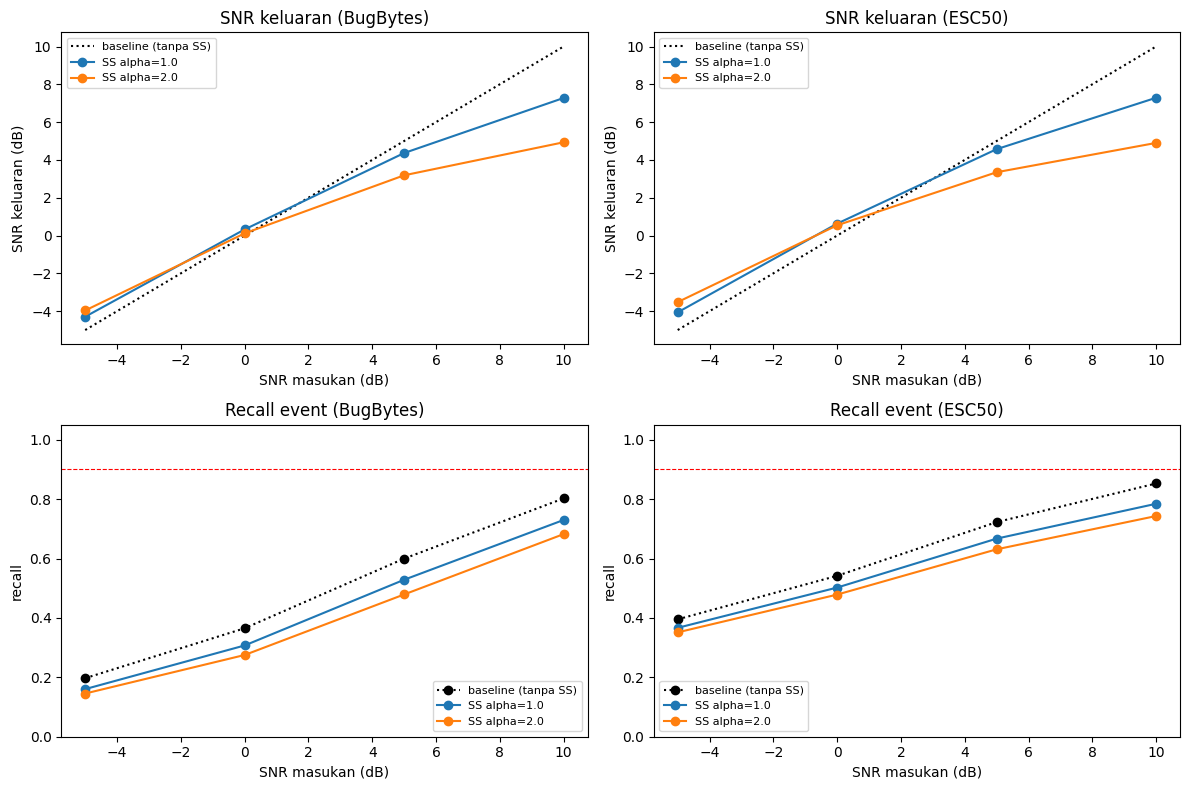

In [10]:
# ringkasan: rerata SNR keluaran dan recall/presisi per kelompok noise, SNR masukan, dan alpha
ring = (eksp.groupby(["noise_grup", "alpha", "snr_in"])
        .agg(snr_ss=("snr_ss", "mean"), delta_snr=("delta_snr", "mean"), delta_sd=("delta_snr", "std"),
             recall_base=("recall_base", "mean"), recall_ss=("recall_ss", "mean"),
             presisi_base=("presisi_base", "mean"), presisi_ss=("presisi_ss", "mean"))
        .round(3).reset_index())
ring.to_csv(f"{RES}/m2_ringkasan_snr_recall.csv", index=False)
display(ring)

# kurva SNR keluaran dan recall terhadap SNR masukan, per kelompok noise
grups = list(eksp.noise_grup.unique())
fig, ax = plt.subplots(2, len(grups), figsize=(6 * len(grups), 8), squeeze=False)
for c, g in enumerate(grups):
    d = eksp[eksp.noise_grup == g]
    ax[0, c].plot(SNR_LIST, SNR_LIST, "k:", label="baseline (tanpa SS)")
    ax[1, c].plot(SNR_LIST, d.groupby("snr_in").recall_base.mean(), "k:", marker="o", label="baseline (tanpa SS)")
    for a in ALPHAS:
        da = d[d.alpha == a]
        ax[0, c].plot(SNR_LIST, da.groupby("snr_in").snr_ss.mean(), marker="o", label=f"SS alpha={a}")
        ax[1, c].plot(SNR_LIST, da.groupby("snr_in").recall_ss.mean(), marker="o", label=f"SS alpha={a}")
    ax[0, c].set(title=f"SNR keluaran ({g})", xlabel="SNR masukan (dB)", ylabel="SNR keluaran (dB)")
    ax[1, c].set(title=f"Recall event ({g})", xlabel="SNR masukan (dB)", ylabel="recall", ylim=(0, 1.05))
    ax[1, c].axhline(0.9, color="r", lw=0.8, ls="--")
    ax[0, c].legend(fontsize=8); ax[1, c].legend(fontsize=8)
fig.tight_layout()
fig.savefig(f"{RES}/m2_kurva_snr_recall.png", dpi=150)
plt.show(); plt.close(fig)

## H2. Spectral subtraction: kenaikan SNR ≥ 3 dB dan recall ≥ 90% (SNR masukan ≥ 0 dB)

Tiap baris tabel = satu kombinasi kelompok noise × alpha × SNR masukan. Uji:
- **Wilcoxon satu arah**: ΔSNR > 3 dB (dan ΔSNR > 0).
- **Wilcoxon berpasangan** recall SS vs baseline (dua arah).
- `recall_ok` = rerata recall SS ≥ 0,9 (relevan untuk SNR masukan ≥ 0 dB).

Dua tingkat ulangan dilaporkan: **per potongan** (sesuai draf, n besar tapi potongan dari file yang sama tidak independen) dan **rerata per file × noise** (lebih konservatif, n kecil). Ukuran efek: rank-biserial.

In [11]:
def wil(d, alt):
    d = np.asarray(d, float); d = d[~np.isnan(d)]
    if len(d) < 5 or np.all(d == 0):
        return np.nan
    return stats.wilcoxon(d, alternative=alt).pvalue

baris = []
agg = (eksp.groupby(["noise_grup", "alpha", "snr_in", "kode", "noise_kunci"])
       .agg(delta_snr=("delta_snr", "mean"), recall_base=("recall_base", "mean"), recall_ss=("recall_ss", "mean"))
       .reset_index())
for (g, a, sn), d in eksp.groupby(["noise_grup", "alpha", "snr_in"]):
    da = agg[(agg.noise_grup == g) & (agg.alpha == a) & (agg.snr_in == sn)]
    baris.append({"noise_grup": g, "alpha": a, "snr_in": sn, "n_run": len(d), "n_agg": len(da),
                  "median_delta_dB": round(d.delta_snr.median(), 2),
                  "p_delta_gt3": wil(d.delta_snr - 3, "greater"),
                  "rb_delta_gt3": round(rank_biserial(d.delta_snr - 3), 2),
                  "p_delta_gt3_agg": wil(da.delta_snr - 3, "greater"),
                  "p_delta_gt0": wil(d.delta_snr, "greater"),
                  "recall_base": round(d.recall_base.mean(), 3), "recall_ss": round(d.recall_ss.mean(), 3),
                  "recall_ok": bool(d.recall_ss.mean() >= 0.9),
                  "p_recall_ss_vs_base": wil((d.recall_ss - d.recall_base).values, "two-sided")})
h2 = pd.DataFrame(baris)
h2.to_csv(f"{RES}/m2_h2_wilcoxon.csv", index=False)
display(h2)

# ringkasan jawaban H2 (hanya SNR masukan >= 0 dB)
sub = h2[h2.snr_in >= 0]
for (g, a), d in sub.groupby(["noise_grup", "alpha"]):
    ok_snr = (d.median_delta_dB >= 3).all() and (d.p_delta_gt3 < ALPHA_SIG).all()
    ok_rec = d.recall_ok.all()
    print(f"{g:9s} alpha={a}: kenaikan SNR >=3 dB (SNR masukan >=0): {'ya' if ok_snr else 'tidak'} | recall >=90%: {'ya' if ok_rec else 'tidak'}")

,noise_grup,alpha,snr_in,n_run,n_agg,median_delta_dB,p_delta_gt3,rb_delta_gt3,p_delta_gt3_agg,p_delta_gt0,recall_base,recall_ss,recall_ok,p_recall_ss_vs_base
0,BugBytes,1.0,-5,420,21,0.53,1.0,-1.00,1.000000,8.322332e-71,0.197,0.160,False,1.420529e-60
1,BugBytes,1.0,0,420,21,0.30,1.0,-1.00,1.000000,3.057580e-24,0.365,0.307,False,6.860107e-67
2,BugBytes,1.0,5,420,21,-0.80,1.0,-1.00,1.000000,1.000000e+00,0.600,0.528,False,1.376755e-68
3,BugBytes,1.0,10,420,21,-3.39,1.0,-1.00,1.000000,1.000000e+00,0.802,0.730,False,9.238266e-67
4,BugBytes,2.0,-5,420,21,0.76,1.0,-1.00,1.000000,5.433460e-69,0.197,0.145,False,1.132182e-61
5,BugBytes,2.0,0,420,21,-0.01,1.0,-1.00,1.000000,9.146979e-02,0.365,0.275,False,3.392872e-67
6,BugBytes,2.0,5,420,21,-2.22,1.0,-1.00,1.000000,1.000000e+00,0.600,0.479,False,3.271617e-69
7,BugBytes,2.0,10,420,21,-6.19,1.0,-1.00,1.000000,1.000000e+00,0.802,0.682,False,1.578581e-67
8,ESC50,1.0,-5,420,21,0.74,1.0,-1.00,1.000000,7.649766e-38,0.395,0.367,False,6.046464e-45
9,ESC50,1.0,0,420,21,0.64,1.0,-1.00,1.000000,8.219676e-25,0.542,0.502,False,3.044589e-51


BugBytes  alpha=1.0: kenaikan SNR >=3 dB (SNR masukan >=0): tidak | recall >=90%: tidak
BugBytes  alpha=2.0: kenaikan SNR >=3 dB (SNR masukan >=0): tidak | recall >=90%: tidak
ESC50     alpha=1.0: kenaikan SNR >=3 dB (SNR masukan >=0): tidak | recall >=90%: tidak
ESC50     alpha=2.0: kenaikan SNR >=3 dB (SNR masukan >=0): tidak | recall >=90%: tidak


## H3. Jumlah getaran naik seiring kepadatan serangga (CSV USDA)

Data USDA berupa CSV fitur getaran (bukan audio). Nama kolomnya belum kita ketahui, jadi sel di bawah **mencari CSV di `../data/raw`, menampilkan kolomnya, dan menebak kolom** spesies / kepadatan / rekaman. Bila tebakan salah, isi `COL_*` secara manual lalu jalankan ulang sel H3.

Jumlah getaran per rekaman = jumlah baris per rekaman (atau kolom `COL_JUMLAH` bila CSV sudah memuat jumlah). Uji: Kruskal–Wallis antar kepadatan dan Spearman (satu arah: jumlah naik seiring kepadatan).

In [12]:
USDA_CSV = None      # contoh: "../data/raw/nama_file_usda.csv" ; None = cari otomatis di RAW
COL_SPESIES = COL_KEPADATAN = COL_REKAMAN = COL_JUMLAH = None   # isi manual bila tebakan salah

if USDA_CSV is None:
    kand = [p for p in sorted(glob.glob(f"{RAW}/*.csv")) if "inventory" not in os.path.basename(p).lower()]
    if len(kand) == 1:
        USDA_CSV = kand[0]
    else:
        print("CSV kandidat di", RAW, ":", [os.path.basename(p) for p in kand])
        print("[!] isi USDA_CSV secara manual bila tidak tepat satu")
usda = None
if USDA_CSV:
    usda = pd.read_csv(USDA_CSV)
    print("file:", os.path.basename(USDA_CSV), usda.shape)
    print("kolom:", list(usda.columns))
    display(usda.head())
    def tebak(pola):
        c = [k for k in usda.columns if re.search(pola, str(k), re.I)]
        return c[0] if c else None
    print("tebakan -> spesies:", tebak("spec|species|spesies|pest"), "| kepadatan:", tebak("dens|kg|infest|level"),
          "| rekaman:", tebak("file|record|sample|trial|rep|id"))

CSV kandidat di ../data/raw : []
[!] isi USDA_CSV secara manual bila tidak tepat satu


In [13]:
if usda is None:
    print("[!] CSV USDA belum dimuat: H3 dilewati")
else:
    def tebak(pola):
        c = [k for k in usda.columns if re.search(pola, str(k), re.I)]
        return c[0] if c else None
    cs = COL_SPESIES or tebak("spec|species|spesies|pest")
    ck = COL_KEPADATAN or tebak("dens|kg|infest|level")
    cr = COL_REKAMAN or tebak("file|record|sample|trial|rep|id")
    print("kolom dipakai -> spesies:", cs, "| kepadatan:", ck, "| rekaman:", cr, "| jumlah:", COL_JUMLAH)
    d = usda.copy()
    d["kepadatan"] = pd.to_numeric(d[ck].astype(str).str.extract(r"(\d+(?:\.\d+)?)")[0], errors="coerce")
    d["spesies_usda"] = d[cs].astype(str) if cs else "semua"
    if COL_JUMLAH:
        per_rek = d.rename(columns={COL_JUMLAH: "jumlah"})[["spesies_usda", "kepadatan", "jumlah"]]
    elif cr:
        per_rek = d.groupby(["spesies_usda", "kepadatan", cr]).size().rename("jumlah").reset_index()
    else:
        per_rek = None
        print("[!] kolom rekaman tidak ditemukan: isi COL_REKAMAN atau COL_JUMLAH")
    if per_rek is not None:
        per_rek = per_rek.dropna(subset=["kepadatan"])
        per_rek.to_csv(f"{RES}/m2_h3_jumlah_per_rekaman.csv", index=False)
        baris = []
        for sp_, g in list(per_rek.groupby("spesies_usda")) + [("SEMUA", per_rek)]:
            lv = [x["jumlah"].values for _, x in g.groupby("kepadatan") if len(x) >= 2]
            if len(lv) < 2:
                continue
            H, pk = stats.kruskal(*lv)
            rho, ps = stats.spearmanr(g["kepadatan"], g["jumlah"], alternative="greater")
            baris.append({"spesies": sp_, "n_rekaman": len(g), "n_level": len(lv),
                          "median_per_level": {k: float(v["jumlah"].median()) for k, v in g.groupby("kepadatan")},
                          "KW_H": round(H, 2), "KW_p": pk, "spearman_rho": round(rho, 3), "spearman_p_greater": ps,
                          "naik_signifikan": bool(ps < ALPHA_SIG)})
        h3 = pd.DataFrame(baris)
        h3.to_csv(f"{RES}/m2_h3_kruskal_spearman.csv", index=False)
        display(h3)

[!] CSV USDA belum dimuat: H3 dilewati


## Checklist akhir minggu 2 (otomatis)

In [14]:
def tanda(ok): return "✓" if ok else "✗"
ada = lambda f: os.path.exists(f"{RES}/{f}")
print(tanda(ada("m2_profil_per_file.csv") and ada("m2_spektrum_per_file.png")), "Profil RMS dan spektrum per spesies dan sensor")
print(tanda(ada("m2_h1_kruskal.csv")), "Kruskal–Wallis (+Dunn) H1")
ok_mix = ("eksp" in globals()) and set(SNR_LIST) == set(eksp.snr_in.unique()) and eksp.potongan.nunique() == N_POTONG
print(tanda(ok_mix), f"{len(SNR_LIST)} SNR × {N_POTONG} campuran")
print(tanda(ada("m2_hasil_eksperimen.csv")), "Spectral subtraction dijalankan (hasil per campuran tersimpan)")
print(tanda(ada("m2_h2_wilcoxon.csv")), "Wilcoxon SNR (H2)")
print(tanda(ada("m2_h3_kruskal_spearman.csv")), "Kruskal–Wallis dan Spearman CSV USDA (H3)")
print(tanda(ada("m2_daftar_file_noise.csv") and ada("m2_parameter.json")), "Daftar file noise dan parameter tersimpan (reproduksibilitas)")

✓ Profil RMS dan spektrum per spesies dan sensor
✓ Kruskal–Wallis (+Dunn) H1
✓ 4 SNR × 20 campuran
✓ Spectral subtraction dijalankan (hasil per campuran tersimpan)
✓ Wilcoxon SNR (H2)
✗ Kruskal–Wallis dan Spearman CSV USDA (H3)
✓ Daftar file noise dan parameter tersimpan (reproduksibilitas)
